# MICROPLASTIC CONTAMINATION VS. MEASUREMENT RELIABILITY

In [31]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

DATA_DIR = ""
FIG_DIR = "figures"
TABLE_DIR = "tables"
OUTPUT_DIR = "cleaned_data"

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

FILES = {
    "mp_quant": "surveympquantification.csv",
    "soil_props": "surveysoilproperties.csv",
    "questionnaire": "surveyquestionnaire.csv",
    "mp_id": "surveympidentification.csv",
    "std_quant": "standardmpquantification.csv",
    "std_polymer": "standardpolymerid.csv",
    "std_lib_uk": "standardpolymerlibrarycomparisonuk.csv",
    "lab_meta": "laboratorymetadata.csv"
}


# 2. LOAD ALL DATASETS

In [32]:

data = {}

for name, filename in FILES.items():

    path = os.path.join(DATA_DIR, filename)

    if os.path.exists(path):

        try:
            data[name] = pd.read_csv(
                path,
                encoding="latin1"
            )

            print(
                f"[OK] {name}: "
                f"{data[name].shape[0]} rows x "
                f"{data[name].shape[1]} columns"
            )

        except Exception as e:

            data[name] = None
            print(f"[ERROR] {filename}: {e}")

    else:

        data[name] = None
        print(f"[MISSING] {filename}")


# Check required datasets

required_datasets = [
    "mp_quant",
    "soil_props",
    "questionnaire"
]

for name in required_datasets:

    if data[name] is None:

        raise FileNotFoundError(
            f"Required dataset is missing: {FILES[name]}"
        )


[OK] mp_quant: 576 rows x 5 columns
[OK] soil_props: 576 rows x 9 columns
[OK] questionnaire: 192 rows x 49 columns
[OK] mp_id: 6851 rows x 5 columns
[OK] std_quant: 188 rows x 4 columns
[OK] std_polymer: 1440 rows x 5 columns
[OK] std_lib_uk: 180 rows x 5 columns
[OK] lab_meta: 8 rows x 45 columns


3. INITIAL DATASET INSPECTION

In [33]:
for name, df in data.items():

    if df is None:
        continue

    print("\n" + "=" * 65)
    print(f"DATASET: {name}")
    print("Shape:", df.shape)
    print("=" * 65)

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 3 rows:")
    display(df.head(3))


DATASET: mp_quant
Shape: (576, 5)

Data types:
Site             str
Country          str
Depth          int64
Z            float64
MP_number    float64
dtype: object

First 3 rows:


,Site,Country,Depth,Z,MP_number
0,E1,Egypt,10,-0.279410,877.381883
1,E1,Egypt,20,-0.662864,744.294969
2,E1,Egypt,30,1.501901,1495.628188



DATASET: soil_props
Shape: (576, 9)

Data types:
Site Code        str
Country          str
Depth          int64
pH           float64
EC           float64
NH4          float64
NO3          float64
DOC          float64
PO4          float64
dtype: object

First 3 rows:


,Site Code,Country,Depth,pH,EC,NH4,NO3,DOC,PO4
0,E1,Egypt,10,8.95,290.0,33.19,2.37,264.28,6.93
1,E1,Egypt,20,9.20,337.0,25.40,3.18,199.75,7.10
2,E1,Egypt,30,9.04,297.0,33.32,3.81,129.42,8.88



DATASET: questionnaire
Shape: (192, 49)

Data types:
Site_Code                              str
Country                                str
Crop                                   str
Tillage                                str
Surface_cultivation                    str
Plough                                 str
Harrow                                 str
Rotavator                              str
Max_cultivation_depth                int64
Soil_classification                    str
Sand                                   str
Loam                                   str
Silt                                   str
Clay                                   str
Annual_average_rainfall            float64
Annual_average_air_temperature     float64
PMF_use_duration                   float64
PMF_type                               str
Ploughing                              str
Burning                                str
Waste_collection                       str
Selling                                str


,Site_Code,Country,Crop,Tillage,Surface_cultivation,Plough,Harrow,Rotavator,Max_cultivation_depth,Soil_classification,...,Sewage_sludge_quantity_per_year,Sewage_sludge_use_duration,Irrigation_pipes,Nets,Greenhouses,Polytunnels,Packaging,Drums,Barriers,Crates
0,E1,Egypt,Vegetable,Yes,Yes,No,No,No,30,Arenosol,...,NaN,NaN,Yes,No,No,No,No,No,No,No
1,E2,Egypt,Vegetable,Yes,Yes,No,No,No,30,Arenosol,...,NaN,NaN,Yes,No,No,No,No,No,No,No
2,E3,Egypt,Vegetable,Yes,Yes,No,No,No,30,Arenosol,...,NaN,NaN,Yes,No,No,No,No,No,No,No


... (6 outputs left out)


DATASET: std_lib_uk
Shape: (180, 5)

Data types:
Library           int64
Sample            int64
Particle          int64
ID                  str
MatchQuality    float64
dtype: object

First 3 rows:


,Library,Sample,Particle,ID,MatchQuality
0,1,1,1,PET,71.1
1,1,1,2,PET,77.6
2,1,1,3,PET,70.5



DATASET: lab_meta
Shape: (8, 45)

Data types:
Country                               str
Instrument_manufacturer               str
Instrument_type                       str
Instrument_model                      str
Location                              str
Library                               str
Soil_weight                           str
Soil_classification                   str
Soil_texture                          str
Membrane_area                     float64
Image_size                            str
Membrane_d                          int64
Real_membrane_d                     int64
Real_membrane_a                   float64
Membrane_type                         str
Pore_size                         float64
Membrane_manufacturer                 str
Membrane_product_number               str
Filtration_system_manufacturer        str
Vacuum_pump_manufacturer              str
Vacuum_pump_type                      str
Microscope_manufacturer               str
Microscope_model             

,Country,Instrument_manufacturer,Instrument_type,Instrument_model,Location,Library,Soil_weight,Soil_classification,Soil_texture,Membrane_area,...,SD_CAS_number,BT_manufacturer,BT_product_number,BT_CAS_number,NaOH_manufacturer,NaOH_product_number,NaOH_CAS_number,NaCl_manufacturer,NaCl_product_number,NaCl_CAS_number
0,UK,Agilent,Quantum cascade laser direct infrared system,LDIR 8700,Bangor University (UK),Instrument library (Agilent Microplastic Start...,5 ± 0.05,Cambisol,Clay-loam,16.05,...,60676-86-0,Sigma Aldrich,285234.0,1302-78-9,Sigma Aldrich,221465,1310-73-2,Sigma Aldrich,S9888,7647-14-5
1,China 1,Bruker,µFTIR,Lumos II,Chinese Academy of Agricultural Sciences (China),Instrument library (incorporated polymer-speci...,5 ± 0.05,Cambisol,Loam,5.00,...,NaN,NaN,NaN,NaN,Heng Xing,30225,NaN,Heng Xing,30144,NaN
2,China 2,NaN,NaN,NaN,NaN,NaN,5 ± 0.05,Umbrisol,Loam,2.00,...,NaN,NaN,NaN,NaN,Sinopharm Chemical Reagent,UN No.1823,NaN,Sinopharm Chemical Reagent,10019318,NaN


 4. INITIAL DATA QUALITY REPORT

In [34]:
quality_reports = []

for name, df in data.items():

    if df is None:
        continue

    report = pd.DataFrame({

        "Dataset": name,
        "Column": df.columns,
        "Data_Type": [
            str(df[col].dtype) for col in df.columns
        ],
        "Missing_Values": [
            int(df[col].isna().sum()) for col in df.columns
        ],
        "Missing_Percentage": [
            round(df[col].isna().mean() * 100, 2)
            for col in df.columns
        ],
        "Unique_Values": [
            int(df[col].nunique()) for col in df.columns
        ]

    })

    quality_reports.append(report)

    print(f"\n{name}:")
    print("Duplicate rows:", df.duplicated().sum())

    display(
        report.sort_values(
            "Missing_Percentage",
            ascending=False
        ).head(15)
    )

quality_report = pd.concat(
    quality_reports,
    ignore_index=True
)

quality_report.to_csv(
    os.path.join(TABLE_DIR, "initial_data_quality_report.csv"),
    index=False
)



mp_quant:
Duplicate rows: 0


,Dataset,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
4,mp_quant,MP_number,float64,4,0.69,443
3,mp_quant,Z,float64,4,0.69,429
0,mp_quant,Site,str,0,0.00,192
2,mp_quant,Depth,int64,0,0.00,3
1,mp_quant,Country,str,0,0.00,5



soil_props:
Duplicate rows: 0


,Dataset,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
7,soil_props,DOC,float64,6,1.04,491
0,soil_props,Site Code,str,0,0.00,192
1,soil_props,Country,str,0,0.00,5
3,soil_props,pH,float64,0,0.00,286
2,soil_props,Depth,int64,0,0.00,3
4,soil_props,EC,float64,0,0.00,503
5,soil_props,NH4,float64,0,0.00,413
6,soil_props,NO3,float64,0,0.00,445
8,soil_props,PO4,float64,0,0.00,524



questionnaire:
Duplicate rows: 0


,Dataset,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
39,questionnaire,Sewage_sludge_quantity_per_year,float64,190,98.96,2
40,questionnaire,Sewage_sludge_use_duration,float64,188,97.92,3
27,questionnaire,Coated_fertiliser_use_duration,float64,158,82.29,8
29,questionnaire,Compost_quantity_per_year,float64,49,25.52,63
37,questionnaire,Compost_use_duration,float64,49,25.52,38
38,questionnaire,Sewage_sludge_use,str,18,9.38,2
2,questionnaire,Crop,str,3,1.56,8
4,questionnaire,Surface_cultivation,str,1,0.52,2
0,questionnaire,Site_Code,str,0,0.00,192
9,questionnaire,Soil_classification,str,0,0.00,14


... (6 outputs left out)


std_lib_uk:
Duplicate rows: 0


,Dataset,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
0,std_lib_uk,Library,int64,0,0.0,2
1,std_lib_uk,Sample,int64,0,0.0,9
2,std_lib_uk,Particle,int64,0,0.0,10
3,std_lib_uk,ID,str,0,0.0,12
4,std_lib_uk,MatchQuality,float64,0,0.0,139



lab_meta:
Duplicate rows: 0


,Dataset,Column,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
41,lab_meta,NaOH_CAS_number,str,7,87.5,1
29,lab_meta,Nile_red_CAS_number,str,7,87.5,1
30,lab_meta,Polyethylene_manufacturer,str,7,87.5,1
31,lab_meta,Polyethylene_product_number,float64,7,87.5,1
32,lab_meta,Polyethylene_CAS_number,str,7,87.5,1
37,lab_meta,BT_product_number,float64,7,87.5,1
38,lab_meta,BT_CAS_number,str,7,87.5,1
44,lab_meta,NaCl_CAS_number,str,7,87.5,1
36,lab_meta,BT_manufacturer,str,7,87.5,1
33,lab_meta,SD_manufacturer,str,7,87.5,1


 5. CLEANING FUNCTIONS

In [35]:

NA_TOKENS = [
    "n/a", "N/A", "na", "NaN", "nan", "", " "
]


def standardise_columns(df):

    df = df.copy()

    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.replace(" ", "_", regex=False)
    )

    return df


def standardise_missing(df):

    df = df.copy()

    df = df.replace(NA_TOKENS, np.nan)

    for col in df.columns:

        if df[col].dtype == "object":

            df[col] = df[col].str.strip()

            df[col] = df[col].replace(
                ["", "nan", "NaN", "n/a", "N/A"],
                np.nan
            )

    return df


def coerce_numeric(df, columns):

    df = df.copy()

    for col in columns:

        if col in df.columns:

            df[col] = pd.to_numeric(
                df[col],
                errors="coerce"
            )

    return df


def save_figure(filename):

    plt.tight_layout()

    plt.savefig(
        os.path.join(FIG_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


 6. STANDARDISE AND CLEAN MAIN SURVEY DATASETS

In [36]:

mpq_raw = standardise_columns(
    data["mp_quant"]
)

soil_raw = standardise_columns(
    data["soil_props"]
)

qn_raw = standardise_columns(
    data["questionnaire"]
)


# Standardise Site column names

for df in [mpq_raw, soil_raw, qn_raw]:

    if "Site_Code" in df.columns and "Site" not in df.columns:

        df.rename(
            columns={"Site_Code": "Site"},
            inplace=True
        )


# MP Quantification

mpq = standardise_missing(mpq_raw.copy())

mpq = coerce_numeric(
    mpq,
    ["Depth", "MP_number"]
)


# Soil Properties

soil = standardise_missing(soil_raw.copy())

soil = coerce_numeric(
    soil,
    ["Depth", "pH", "EC", "NH4", "NO3", "DOC", "PO4"]
)


# Questionnaire

qn = standardise_missing(qn_raw.copy())

qn = coerce_numeric(
    qn,
    [
        "Max_cultivation_depth",
        "Annual_average_rainfall",
        "Annual_average_air_temperature",
        "Annual_average_air_tem",
        "PMF_use_duration",
        "Compost_quantity_per_year",
        "Compost_use_duration"
    ]
)

# Handle possible alternative temperature column name

if (
    "Annual_average_air_tem" in qn.columns
    and "Annual_average_air_temperature" not in qn.columns
):

    qn.rename(
        columns={
            "Annual_average_air_tem":
            "Annual_average_air_temperature"
        },
        inplace=True
    )


print("MP Quantification:", mpq.shape)
print("Soil Properties:", soil.shape)
print("Questionnaire:", qn.shape)



MP Quantification: (576, 5)
Soil Properties: (576, 9)
Questionnaire: (192, 49)


 7. BEFORE AND AFTER CLEANING REPORT

In [37]:

print("\nMissing values BEFORE cleaning:")

display(mpq_raw.isna().sum().to_frame("Missing_Before"))

print("\nMissing values AFTER cleaning:")

display(mpq.isna().sum().to_frame("Missing_After"))

missing_comparison = pd.DataFrame({

    "Missing_Before": mpq_raw.isna().sum(),

    "Missing_After": mpq.isna().sum()

})

missing_comparison.to_csv(
    os.path.join(TABLE_DIR, "missing_value_comparison.csv")
)




Missing values BEFORE cleaning:


,Missing_Before
Site,0
Country,0
Depth,0
Z,4
MP_number,4



Missing values AFTER cleaning:


,Missing_After
Site,0
Country,0
Depth,0
Z,4
MP_number,4


 8. DATA VALIDATION

In [38]:

print("\n" + "=" * 65)
print("DATA VALIDATION")
print("=" * 65)

if "Depth" in mpq.columns:

    bad_depth = mpq.loc[
        ~mpq["Depth"].isin([10, 20, 30])
        & mpq["Depth"].notna()
    ]

    print("Unexpected depth values:", len(bad_depth))


if "MP_number" in mpq.columns:

    print(
        "Negative MP_number values:",
        int((mpq["MP_number"] < 0).sum())
    )


merge_keys = ["Site", "Country", "Depth"]

for name, df in [("MP Quantification", mpq), ("Soil Properties", soil)]:

    missing_keys = [
        col for col in merge_keys
        if col not in df.columns
    ]

    if missing_keys:

        raise ValueError(
            f"{name} is missing merge columns: {missing_keys}"
        )

    print(
        f"{name} duplicate merge keys:",
        df.duplicated(subset=merge_keys).sum()
    )

    print(
        f"{name} missing merge keys:",
        df[merge_keys].isna().sum().to_dict()
    )


# Do not merge records with missing keys

if mpq[merge_keys].isna().any().any():

    raise ValueError(
        "MP quantification contains missing merge keys. "
        "Inspect these rows before merging."
    )

if soil[merge_keys].isna().any().any():

    raise ValueError(
        "Soil properties contains missing merge keys. "
        "Inspect these rows before merging."
    )

if mpq.duplicated(subset=merge_keys).any():

    raise ValueError(
        "Duplicate MP quantification merge keys found. "
        "Inspect them before merging."
    )

if soil.duplicated(subset=merge_keys).any():

    raise ValueError(
        "Duplicate soil-property merge keys found. "
        "Inspect them before merging."
    )




DATA VALIDATION
Unexpected depth values: 0
Negative MP_number values: 0
MP Quantification duplicate merge keys: 0
MP Quantification missing merge keys: {'Site': 0, 'Country': 0, 'Depth': 0}
Soil Properties duplicate merge keys: 0
Soil Properties missing merge keys: {'Site': 0, 'Country': 0, 'Depth': 0}


9. MISSING VALUE VISUALISATION

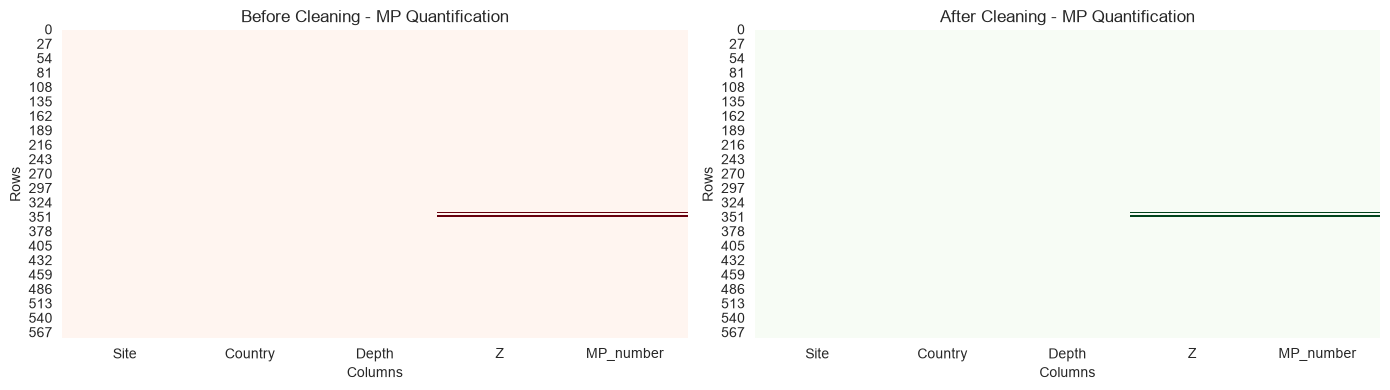

In [39]:

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.heatmap(
    mpq_raw.isna(),
    cbar=False,
    cmap="Reds",
    ax=axes[0]
)

axes[0].set_title("Before Cleaning - MP Quantification")
axes[0].set_xlabel("Columns")
axes[0].set_ylabel("Rows")

sns.heatmap(
    mpq.isna(),
    cbar=False,
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("After Cleaning - MP Quantification")
axes[1].set_xlabel("Columns")
axes[1].set_ylabel("Rows")

save_figure("fig1_missing_before_after.png")



 10. SAFE MASTER DATASET MERGING

In [40]:


master = mpq.merge(
    soil,
    on=merge_keys,
    how="left",
    validate="one_to_one",
    indicator="soil_merge"
)

print("\nSoil merge results:")
print(master["soil_merge"].value_counts())

master.drop(
    columns="soil_merge",
    inplace=True
)


# Questionnaire duplicate checking

questionnaire_keys = ["Site", "Country"]

if not set(questionnaire_keys).issubset(qn.columns):

    raise ValueError(
        "Questionnaire is missing Site or Country."
    )


# Remove only exact duplicate questionnaire rows

qn_unique = qn.drop_duplicates().copy()

# Check for different records with the same site and country

conflicting_keys = qn_unique.duplicated(
    subset=questionnaire_keys,
    keep=False
)

if conflicting_keys.any():

    print("\nWARNING: Conflicting questionnaire records found.")

    display(
        qn_unique.loc[conflicting_keys].sort_values(
            questionnaire_keys
        )
    )

    raise ValueError(
        "Questionnaire merge stopped because different records "
        "share the same Site and Country."
    )


master = master.merge(
    qn_unique,
    on=questionnaire_keys,
    how="left",
    validate="many_to_one",
    indicator="questionnaire_merge",
    suffixes=("", "_qn")
)

print("\nQuestionnaire merge results:")
print(master["questionnaire_merge"].value_counts())

master.drop(
    columns="questionnaire_merge",
    inplace=True
)


assert len(master) == len(mpq), (
    "Master dataset row count changed after merging."
)

print("\nMaster dataset successfully created.")

print("MP quantification rows:", len(mpq))
print("Master dataset rows:", len(master))
print("Unique sites:", master["Site"].nunique())
print("Unique countries:", master["Country"].nunique())

display(master.head())


Soil merge results:
soil_merge
both          576
left_only       0
right_only      0
Name: count, dtype: int64

Questionnaire merge results:
questionnaire_merge
both          576
left_only       0
right_only      0
Name: count, dtype: int64

Master dataset successfully created.
MP quantification rows: 576
Master dataset rows: 576
Unique sites: 192
Unique countries: 5


,Site,Country,Depth,Z,MP_number,pH,EC,NH4,NO3,DOC,...,Sewage_sludge_quantity_per_year,Sewage_sludge_use_duration,Irrigation_pipes,Nets,Greenhouses,Polytunnels,Packaging,Drums,Barriers,Crates
0,E1,Egypt,10,-0.279410,877.381883,8.95,290.0,33.19,2.37,264.28,...,NaN,NaN,Yes,No,No,No,No,No,No,No
1,E1,Egypt,20,-0.662864,744.294969,9.20,337.0,25.40,3.18,199.75,...,NaN,NaN,Yes,No,No,No,No,No,No,No
2,E1,Egypt,30,1.501901,1495.628188,9.04,297.0,33.32,3.81,129.42,...,NaN,NaN,Yes,No,No,No,No,No,No,No
3,E2,Egypt,10,0.257006,1063.557822,8.77,519.0,39.67,4.60,449.28,...,NaN,NaN,Yes,No,No,No,No,No,No,No
4,E2,Egypt,20,2.405999,1809.416847,8.82,488.0,21.98,4.87,428.75,...,NaN,NaN,Yes,No,No,No,No,No,No,No


11. MP CONCENTRATION BY COUNTRY

In [41]:


country_summary = master.groupby(
    "Country",
    observed=True
)["MP_number"].agg(
    n="count",
    mean="mean",
    median="median",
    std="std",
    min="min",
    max="max"
).round(2)

print("\nMP Concentration by Country:")

display(country_summary)

country_summary.to_csv(
    os.path.join(TABLE_DIR, "mp_by_country_summary.csv")
)




MP Concentration by Country:


,n,mean,median,std,min,max
Country,,,,,,
China,120,76.57,41.38,91.94,2.68,570.00
Egypt,120,1122.68,974.36,711.38,230.21,5861.86
India,96,69.56,59.46,42.92,0.00,190.29
Sri Lanka,116,3136.71,1110.89,5931.86,2.76,42549.63
Vietnam,120,5.32,4.40,5.22,0.60,53.80


 12. LOG TRANSFORMATION

In [42]:
master["log_MP"] = np.log1p(
    master["MP_number"]
)

 13. RAW AND LOG MP CONCENTRATION BY COUNTRY


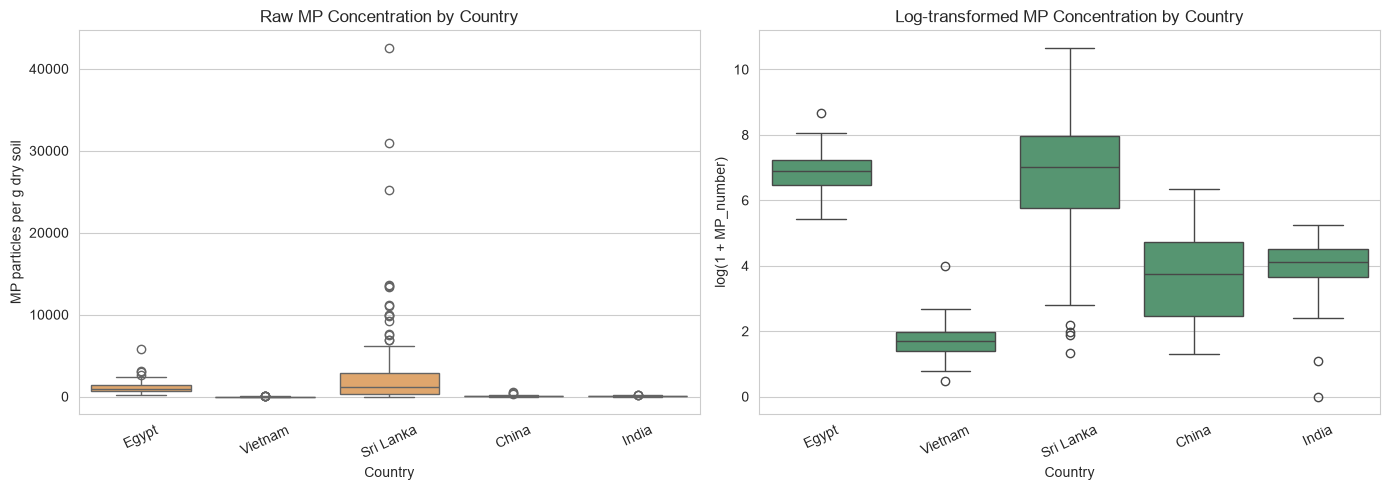

In [43]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=master,
    x="Country",
    y="MP_number",
    ax=axes[0],
    color="#f2a65a"
)

axes[0].set_title("Raw MP Concentration by Country")
axes[0].set_ylabel("MP particles per g dry soil")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(
    data=master,
    x="Country",
    y="log_MP",
    ax=axes[1],
    color="#4c9f70"
)

axes[1].set_title("Log-transformed MP Concentration by Country")
axes[1].set_ylabel("log(1 + MP_number)")
axes[1].tick_params(axis="x", rotation=25)

save_figure("fig2_raw_vs_log.png")

 14. MP CONCENTRATION BY DEPTH

C:\Users\Nishat PC\AppData\Local\Temp\ipykernel_23496\105207090.py:7: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=('ci', 68)` for the same effect.

  sns.lineplot(


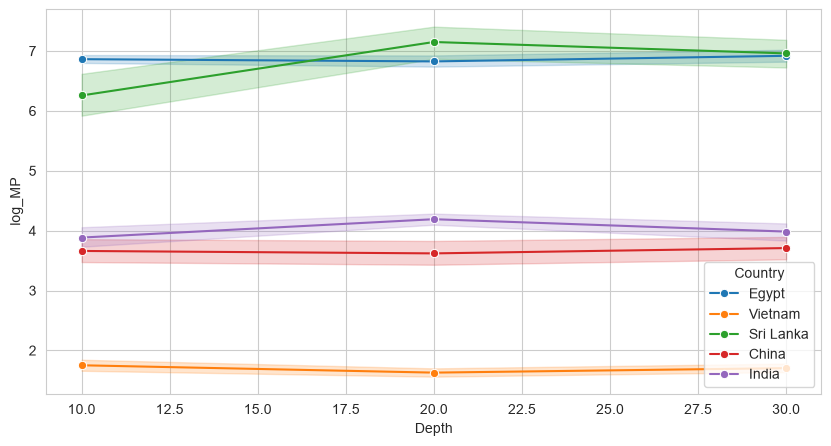

In [44]:
depth_data = master.dropna(
    subset=["Depth", "MP_number", "Country", "log_MP"]
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=depth_data,
    x="Depth",
    y="log_MP",
    hue="Country",
    marker="o",
    estimator="mean",
    ci=68,
    ax=ax
)
def save_figure(filename):

    plt.tight_layout()

    plt.savefig(
        os.path.join(FIG_DIR, filename),
        dpi=300
    )

    plt.show()
    plt.close()

15. MP DISTRIBUTION

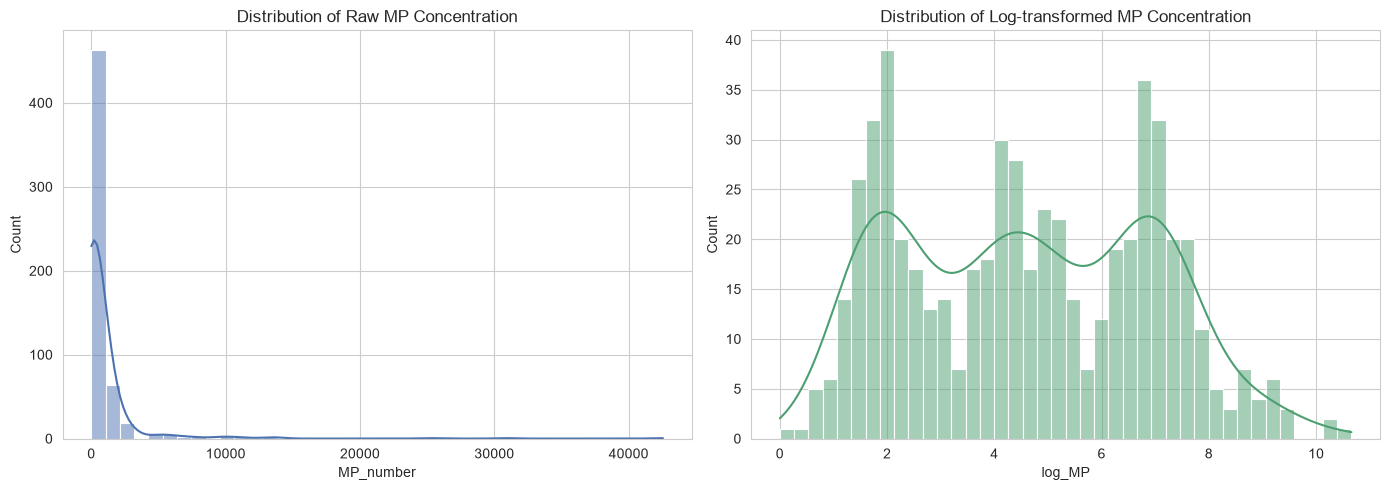

In [45]:


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    master["MP_number"].dropna(),
    bins=40,
    kde=True,
    color="#4c72b0",
    ax=axes[0]
)

axes[0].set_title("Distribution of Raw MP Concentration")

sns.histplot(
    master["log_MP"].dropna(),
    bins=40,
    kde=True,
    color="#4c9f70",
    ax=axes[1]
)

axes[1].set_title("Distribution of Log-transformed MP Concentration")

save_figure("fig4_distribution.png")



 16. SOIL PROPERTIES AND MP ASSOCIATION

In [46]:


numeric_vars = [
    "pH",
    "EC",
    "NH4",
    "NO3",
    "DOC",
    "PO4",
    "Annual_average_rainfall",
    "Annual_average_air_temperature",
    "PMF_use_duration"
]

numeric_vars = [
    col for col in numeric_vars
    if col in master.columns
]

association_rows = []

for variable in numeric_vars:

    pair = master[["log_MP", variable]].copy()

    pair[variable] = pd.to_numeric(
        pair[variable],
        errors="coerce"
    )

    pair = pair.dropna()

    if len(pair) >= 5:

        r = pair["log_MP"].corr(
            pair[variable],
            method="spearman"
        )

        association_rows.append({

            "Variable": variable,
            "Number_of_Pairs": len(pair),
            "Spearman_Correlation": round(r, 3)

        })


association = pd.DataFrame(association_rows)

if not association.empty:

    association["Absolute_Correlation"] = (
        association["Spearman_Correlation"].abs()
    )

    association = association.sort_values(
        "Absolute_Correlation",
        ascending=False
    )

    association.drop(
        columns="Absolute_Correlation",
        inplace=True
    )

    display(association)

    association.to_csv(
        os.path.join(TABLE_DIR, "spearman_associations.csv"),
        index=False
    )


,Variable,Number_of_Pairs,Spearman_Correlation
2,NH4,572,0.595
4,DOC,566,0.541
8,PMF_use_duration,572,-0.453
6,Annual_average_rainfall,572,-0.416
5,PO4,572,-0.412
7,Annual_average_air_temperature,572,0.358
1,EC,572,-0.306
3,NO3,572,0.242
0,pH,572,0.219


17. SPEARMAN CORRELATION HEATMAP

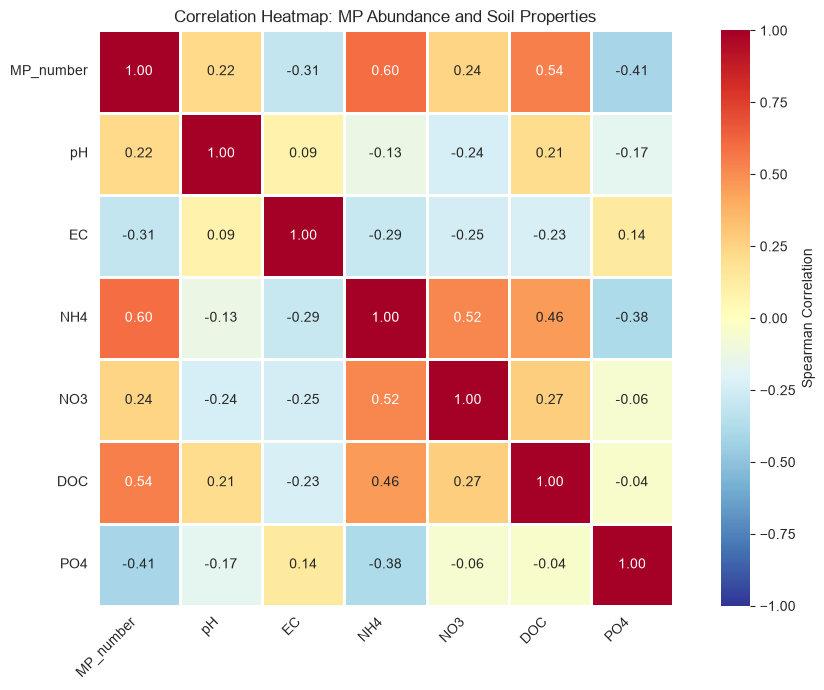

,MP_number,pH,EC,NH4,NO3,DOC,PO4
MP_number,1.000,0.219,-0.306,0.595,0.242,0.541,-0.412
pH,0.219,1.000,0.085,-0.132,-0.241,0.208,-0.165
EC,-0.306,0.085,1.000,-0.295,-0.245,-0.234,0.138
NH4,0.595,-0.132,-0.295,1.000,0.523,0.455,-0.384
NO3,0.242,-0.241,-0.245,0.523,1.000,0.267,-0.059
DOC,0.541,0.208,-0.234,0.455,0.267,1.000,-0.040
PO4,-0.412,-0.165,0.138,-0.384,-0.059,-0.040,1.000


In [47]:


correlation_columns = [
    "MP_number",
    "pH",
    "EC",
    "NH4",
    "NO3",
    "DOC",
    "PO4"
]

available_columns = [
    col for col in correlation_columns
    if col in master.columns
]

corr_data = master[available_columns].copy()

for col in corr_data.columns:

    corr_data[col] = pd.to_numeric(
        corr_data[col],
        errors="coerce"
    )

correlation_matrix = corr_data.corr(
    method="spearman"
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="RdYlBu_r",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.8,
    square=True,
    cbar_kws={
        "label": "Spearman Correlation"
    }
)

plt.title(
    "Correlation Heatmap: MP Abundance and Soil Properties"
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

save_figure("fig5_spearman_heatmap.png")

display(correlation_matrix.round(3))

correlation_matrix.to_csv(
    os.path.join(TABLE_DIR, "spearman_correlation_matrix.csv")
)


18. ENVIRONMENTAL POLYMER IDENTIFICATION


Environmental MP Identification Shape: (6851, 5)
Exact duplicate rows: 236

Duplicate Sensitivity Analysis:


,Count_With_All_Rows,Count_Without_Exact_Duplicates,Difference
ID,,,
Rubber,2212,2067,145
PA,2064,2025,39
PS,515,490,25
PET,444,442,2
PP,408,403,5
PE,330,326,4
PU,192,182,10
PVA,164,162,2
PVC,115,114,1


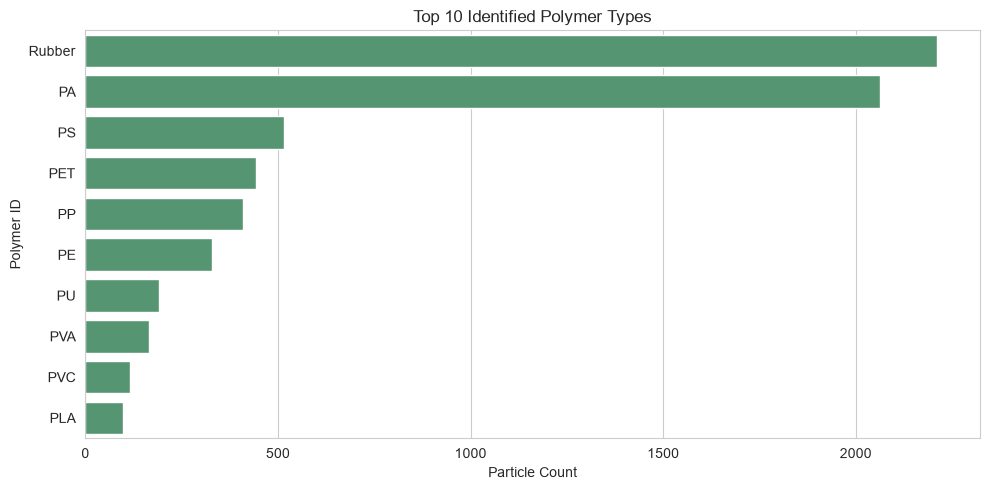

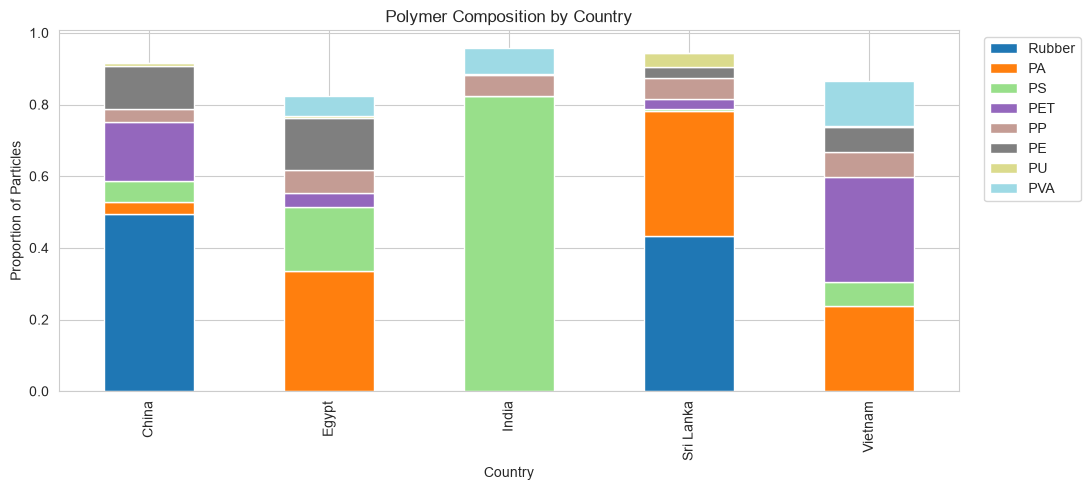


Environmental Identification Match Quality:


count    6851.000000
mean       82.189542
std        11.316900
min        10.600000
25%        80.790000
50%        83.240000
75%        87.360000
max        99.210000
Name: Quality, dtype: float64

,count,mean,median,std
Country,,,,
China,300,40.58,40.15,15.67
Egypt,574,80.79,79.80,9.88
India,387,78.60,81.44,8.95
Sri Lanka,4760,84.67,83.42,4.14
Vietnam,830,85.64,87.65,9.24


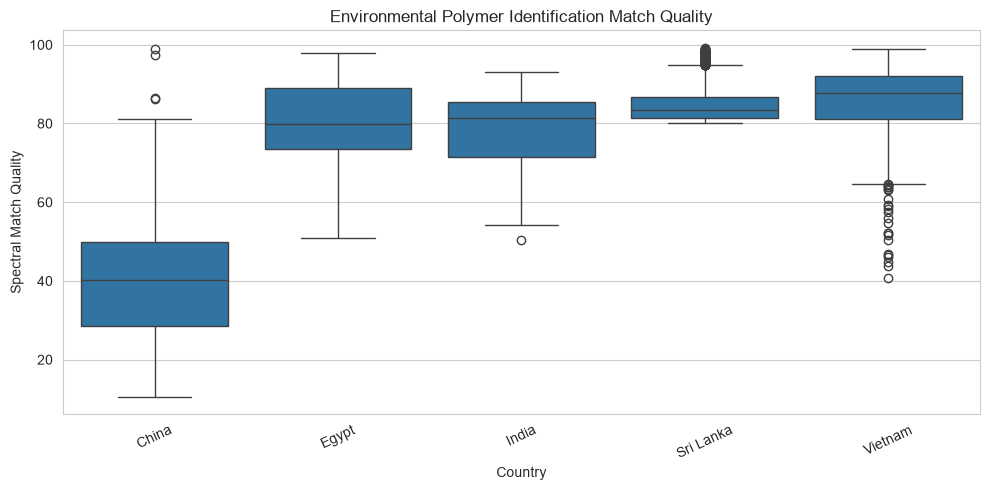


Quality Duplicate Sensitivity:


,With_All_Rows,Without_Exact_Duplicates
Count,6851.000000,6615.000000
Mean,82.189542,82.169303
Median,83.240000,83.250000


In [48]:
if data["mp_id"] is not None:

    mpid = standardise_columns(
        data["mp_id"]
    )

    mpid = standardise_missing(mpid)

    print("\nEnvironmental MP Identification Shape:", mpid.shape)

    duplicate_count = int(mpid.duplicated().sum())

    print("Exact duplicate rows:", duplicate_count)

    if "ID" in mpid.columns:

        mpid["ID"] = mpid["ID"].fillna("Unidentified")

        # Polymer counts with all recorded rows

        counts_all = mpid["ID"].value_counts()

        # Sensitivity analysis: compare with exact duplicates excluded

        mpid_no_exact_duplicates = mpid.drop_duplicates().copy()

        counts_without_duplicates = (
            mpid_no_exact_duplicates["ID"].value_counts()
        )

        duplicate_comparison = pd.concat(
            [
                counts_all.rename("Count_With_All_Rows"),
                counts_without_duplicates.rename(
                    "Count_Without_Exact_Duplicates"
                )
            ],
            axis=1
        ).fillna(0).astype(int)

        duplicate_comparison["Difference"] = (
            duplicate_comparison["Count_With_All_Rows"]
            - duplicate_comparison["Count_Without_Exact_Duplicates"]
        )

        print("\nDuplicate Sensitivity Analysis:")

        display(duplicate_comparison)

        duplicate_comparison.to_csv(
            os.path.join(
                TABLE_DIR,
                "polymer_duplicate_sensitivity.csv"
            )
        )

        # Top 10 polymer types using all recorded rows

        top_types = counts_all.head(10)

        plt.figure(figsize=(10, 5))

        sns.barplot(
            x=top_types.values,
            y=top_types.index,
            color="#4c9f70"
        )

        plt.title("Top 10 Identified Polymer Types")
        plt.xlabel("Particle Count")
        plt.ylabel("Polymer ID")

        save_figure("fig6_top_polymers.png")


        # Polymer composition by country

        if "Country" in mpid.columns:

            comp = mpid.groupby(
                ["Country", "ID"]
            ).size().unstack(fill_value=0)

            keep = (
                comp.sum()
                .sort_values(ascending=False)
                .head(8)
                .index
            )

            prop = comp[keep].div(
                comp.sum(axis=1).replace(0, np.nan),
                axis=0
            )

            prop.plot(
                kind="bar",
                stacked=True,
                figsize=(11, 5),
                colormap="tab20"
            )

            plt.title("Polymer Composition by Country")
            plt.ylabel("Proportion of Particles")
            plt.xlabel("Country")

            plt.legend(
                bbox_to_anchor=(1.02, 1),
                loc="upper left"
            )

            save_figure("fig7_polymer_composition.png")


    # Environmental identification quality

    if "Quality" in mpid.columns:

        mpid["Quality"] = pd.to_numeric(
            mpid["Quality"],
            errors="coerce"
        )

        print("\nEnvironmental Identification Match Quality:")

        display(mpid["Quality"].describe())

        if "Country" in mpid.columns:

            quality_summary = mpid.groupby(
                "Country"
            )["Quality"].agg(
                ["count", "mean", "median", "std"]
            ).round(2)

            display(quality_summary)

            quality_summary.to_csv(
                os.path.join(
                    TABLE_DIR,
                    "environmental_match_quality_by_country.csv"
                )
            )

            plt.figure(figsize=(10, 5))

            sns.boxplot(
                data=mpid,
                x="Country",
                y="Quality"
            )

            plt.title(
                "Environmental Polymer Identification Match Quality"
            )

            plt.ylabel("Spectral Match Quality")
            plt.xticks(rotation=25)

            save_figure("fig8_environmental_match_quality.png")


    # Compare quality results with and without exact duplicates

    if "Quality" in mpid.columns:

        quality_duplicate_comparison = pd.DataFrame({

            "With_All_Rows": [
                mpid["Quality"].count(),
                mpid["Quality"].mean(),
                mpid["Quality"].median()
            ],

            "Without_Exact_Duplicates": [
                mpid_no_exact_duplicates["Quality"].count(),
                mpid_no_exact_duplicates["Quality"].mean(),
                mpid_no_exact_duplicates["Quality"].median()
            ]

        }, index=["Count", "Mean", "Median"])

        print("\nQuality Duplicate Sensitivity:")

        display(quality_duplicate_comparison)

        quality_duplicate_comparison.to_csv(
            os.path.join(
                TABLE_DIR,
                "quality_duplicate_sensitivity.csv"
            )
        )



 19. STANDARD POLYMER IDENTIFICATION


Standard Polymer Match Quality:


count    1330.000000
mean       90.149038
std         8.635818
min        47.200000
25%        84.537500
50%        93.100000
75%        97.000000
max       100.000000
Name: MatchQuality, dtype: float64

,count,mean,median,std,min,max
Country,,,,,,
Australia,240,92.24,95.46,7.25,63.79,99.09
China,240,90.82,94.91,9.02,47.20,99.17
Egypt,240,91.52,97.00,9.41,56.00,100.00
India,130,94.71,96.92,6.43,75.17,99.82
UK,240,87.88,88.65,8.19,60.00,99.50
Vietnam,240,85.81,87.06,7.78,57.31,98.39


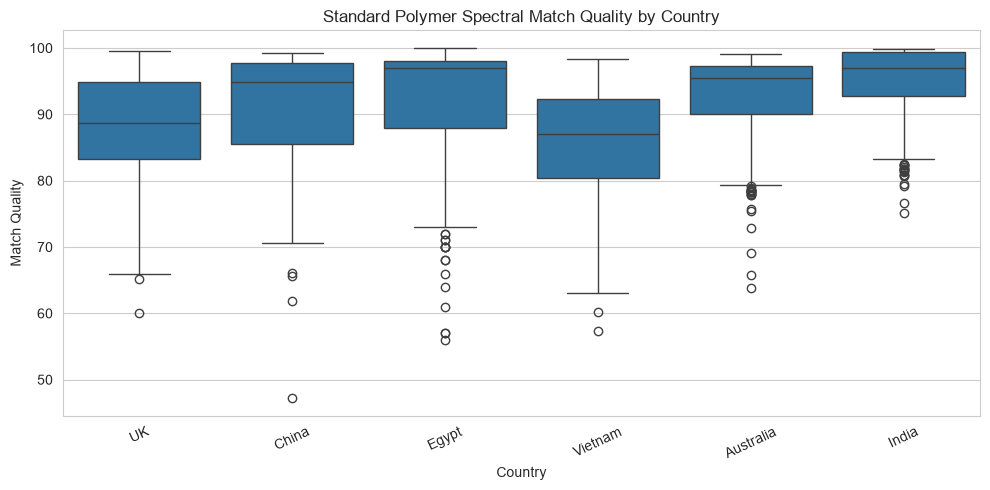

,Count
ID,
PVC,215
PA,210
PS,151
PET,130
PE,130
PC,127
PU,117
NaN,110
PTFE,101


In [49]:

if data["std_polymer"] is not None:

    stdpoly = standardise_columns(
        data["std_polymer"]
    )

    stdpoly = standardise_missing(stdpoly)

    if "MatchQuality" in stdpoly.columns:

        stdpoly["MatchQuality"] = pd.to_numeric(
            stdpoly["MatchQuality"],
            errors="coerce"
        )

        print("\nStandard Polymer Match Quality:")

        display(stdpoly["MatchQuality"].describe())

        if "Country" in stdpoly.columns:

            stdpoly_summary = stdpoly.groupby(
                "Country"
            )["MatchQuality"].agg(
                ["count", "mean", "median", "std", "min", "max"]
            ).round(2)

            display(stdpoly_summary)

            stdpoly_summary.to_csv(
                os.path.join(
                    TABLE_DIR,
                    "standard_polymer_quality_by_country.csv"
                )
            )

            plt.figure(figsize=(10, 5))

            sns.boxplot(
                data=stdpoly,
                x="Country",
                y="MatchQuality"
            )

            plt.title("Standard Polymer Spectral Match Quality by Country")
            plt.ylabel("Match Quality")
            plt.xticks(rotation=25)

            save_figure("fig9_standard_polymer_quality.png")

        if "ID" in stdpoly.columns:

            polymer_counts = stdpoly["ID"].value_counts(
                dropna=False
            )

            display(polymer_counts.to_frame("Count"))

            polymer_counts.to_csv(
                os.path.join(
                    TABLE_DIR,
                    "standard_polymer_identification_counts.csv"
                )
            )







20. POLYMER REFERENCE LIBRARY COMPARISON


Library Match Quality Summary:


,count,mean,median,std,min,max
Library,,,,,,
1,90,81.28,80.4,10.03,61.6,96.7
2,90,91.90,91.8,6.25,60.0,99.5



Paired Library Comparison:


Library             1     2
Sample Particle            
1      1         71.1  92.9
       2         77.6  92.9
       3         70.5  93.7
       4         75.9  96.1
       5         78.2  91.6
...               ...   ...
9      6         80.1  95.9
       7         79.3  96.8
       8         70.9  94.5
       9         84.4  60.0
       10        79.5  97.1

[90 rows x 2 columns]


Paired Comparison Results:
Number of matched pairs: 90
Mean difference: 10.62
Median difference: 11.45


Library             1     2  Difference
Sample Particle                        
1      1         71.1  92.9        21.8
       2         77.6  92.9        15.3
       3         70.5  93.7        23.2
       4         75.9  96.1        20.2
       5         78.2  91.6        13.4
...               ...   ...         ...
9      6         80.1  95.9        15.8
       7         79.3  96.8        17.5
       8         70.9  94.5        23.6
       9         84.4  60.0       -24.4
       10        79.5  97.1        17.6

[90 rows x 3 columns]

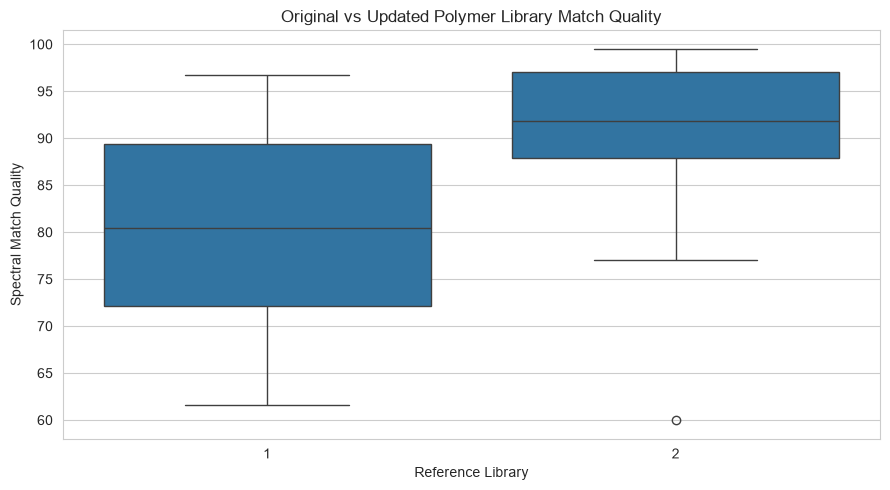

In [50]:
if data["std_lib_uk"] is not None:

    lib = standardise_columns(
        data["std_lib_uk"]
    )

    lib = standardise_missing(lib)

    required_lib_columns = [
        "Library",
        "Sample",
        "Particle",
        "MatchQuality"
    ]

    if set(required_lib_columns).issubset(lib.columns):

        lib["MatchQuality"] = pd.to_numeric(
            lib["MatchQuality"],
            errors="coerce"
        )

        lib["Library"] = lib["Library"].astype(str).str.strip()

        # Summary by library

        library_summary = lib.groupby(
            "Library"
        )["MatchQuality"].agg(
            ["count", "mean", "median", "std", "min", "max"]
        ).round(2)

        print("\nLibrary Match Quality Summary:")

        display(library_summary)

        library_summary.to_csv(
            os.path.join(
                TABLE_DIR,
                "library_quality_summary.csv"
            )
        )

        # Compare the same sample-particle combinations

        paired = lib.pivot_table(
            index=["Sample", "Particle"],
            columns="Library",
            values="MatchQuality",
            aggfunc="mean"
        )

        print("\nPaired Library Comparison:")

        display(paired)

        library_labels = list(paired.columns)

        if len(library_labels) == 2:

            paired_complete = paired.dropna(
                subset=library_labels
            ).copy()

            first_library = library_labels[0]
            second_library = library_labels[1]

            paired_complete["Difference"] = (
                paired_complete[second_library]
                - paired_complete[first_library]
            )

            print("\nPaired Comparison Results:")

            print(
                "Number of matched pairs:",
                len(paired_complete)
            )

            print(
                "Mean difference:",
                round(paired_complete["Difference"].mean(), 2)
            )

            print(
                "Median difference:",
                round(paired_complete["Difference"].median(), 2)
            )

            display(paired_complete)

            paired_complete.to_csv(
                os.path.join(
                    TABLE_DIR,
                    "paired_library_comparison.csv"
                )
            )

        else:

            print(
                "Paired comparison skipped: "
                "exactly two library versions were not found."
            )

        # Visual comparison

        plt.figure(figsize=(9, 5))

        sns.boxplot(
            data=lib,
            x="Library",
            y="MatchQuality"
        )

        plt.title("Original vs Updated Polymer Library Match Quality")
        plt.xlabel("Reference Library")
        plt.ylabel("Spectral Match Quality")

        save_figure("fig10_library_comparison.png")


21. STANDARD MICROPLASTIC QUANTIFICATION


Standard Sample Categories:
Sample
Blank            31
BT 0.04%         27
BT 0%            26
Soil 0%          26
SD 0%            25
SD 0.04%         25
Soil 0.04%       25
PE only 0.04%     3
Name: count, dtype: Int64

Standard Quantification by Sample:


,count,mean,median,std,min,max
Sample,,,,,,
BT 0%,26,394.64,100.00,776.52,1.80,3246.90
BT 0.04%,27,2203.08,1373.64,2426.02,74.77,9980.00
Blank,31,58.68,13.33,137.86,0.00,634.84
PE only 0.04%,3,5209.14,4741.43,1139.82,4377.57,6508.41
SD 0%,25,312.56,170.00,506.35,2.80,2209.66
SD 0.04%,25,2133.25,1533.79,1962.52,220.00,7900.00
Soil 0%,26,161.98,147.90,152.30,2.60,483.94
Soil 0.04%,25,1370.11,685.60,1587.19,93.46,6580.00


count     mean   median      std      min      max
Country   Sample                                                           
Australia BT 0%              4   209.85   226.00    94.66    85.00   302.40
          BT 0.04%           4  1282.65   976.90  1241.73   137.20  3039.60
          Blank              4     3.05     2.80     2.50     0.60     6.00
          SD 0%              4   289.05   316.70   188.17    60.80   462.00
          SD 0.04%           4   406.00   230.20   358.45   220.00   943.60
          Soil 0%            4   235.95   232.90    89.01   155.80   322.20
          Soil 0.04%         4   687.10   627.80   337.34   346.00  1146.80
China_1   BT 0%              3   352.67   306.00   340.41    38.00   714.00
          BT 0.04%           3  7211.33  6400.00  2465.25  5254.00  9980.00
          Blank              9    11.11    13.33     7.45     0.00    20.00
          SD 0%              3   150.00    96.00   111.30    76.00   278.00
          SD 0.04%           3  5926.67  5906.00  1963.08  3974.00  7900.00
          Soil 0%            3   260.00   264.00   118.05   140.00   376.00
          Soil 0.04%         3  1622.67  1260.00   833.44  1032.00  2576.00
China_2   BT 0%              3    93.33    90.00    15.28    80.00   110.00
          BT 0.04%           3  1653.33  1750.00   258.91  1360.00  1850.00
          Blank              3    30.00    40.00    26.46     0.00    50.00
          SD 0%              3   306.67   250.00   172.14   170.00   500.00
          SD 0.04%           3  3633.33  3300.00   831.71  3020.00  4580.00
          Soil 0%            3   183.33   160.00    87.37   110.00   280.00
          Soil 0.04%         3  4390.00  3350.00  1897.39  3240.00  6580.00
Egypt     BT 0%              4   228.11   218.21    94.04   132.86   343.16
          BT 0.04%           5   253.06   197.98   177.63   118.79   558.73
          Blank              3   117.61   114.39     7.98   111.75   126.70
          SD 0%              3   291.54   268.37    40.90   267.49   338.76
          SD 0.04%           3   544.07   554.33    20.11   520.90   556.97
          Soil 0%            4   322.26   324.24   146.79   156.62   483.94
          Soil 0.04%         3   458.42   307.96   302.69   260.45   806.86
India     BT 0%              3    51.54    41.63    31.90    25.77    87.22
          BT 0.04%           3  1310.21  1373.64   222.93  1062.44  1494.55
          Blank              3    25.77    27.75     5.24    19.82    29.73
          SD 0%              3    30.39    27.75     6.37    25.77    37.66
          SD 0.04%           3  2320.45  2315.16  1224.98  1098.12  3548.07
          Soil 0%            3    12.55    11.89     4.99     7.93    17.84
          Soil 0.04%         3   259.00   259.66   119.92   138.75   378.59
Sri Lanka BT 0%              3  2327.36  2380.69   947.33  1354.48  3246.90
          BT 0.04%           3  3517.24  1966.90  2733.20  1911.72  6673.10
          Blank              3   381.73   471.72   308.13    38.62   634.84
          SD 0%              3  1429.89  1495.17   814.38   584.83  2209.66
          SD 0.04%           3  1097.01  1086.90   431.81   670.34  1533.79
          Soil 0%            3   189.43   113.10   200.19    38.62   416.55
          Soil 0.04%         3   592.18   433.10   519.30   171.03  1172.41
UK        BT 0%              3     9.14     8.72     0.72     8.72     9.97
          BT 0.04%           3   595.64   842.37   451.30    74.77   869.78
          Blank              3    12.88    12.46     1.90    11.21    14.95
          PE only 0.04%      3  5209.14  4741.43  1139.82  4377.57  6508.41
          SD 0%              3     7.89     8.72     3.81     3.74    11.21
          SD 0.04%           3  1040.91   892.21   889.13   235.51  1995.02
          Soil 0%            3    10.80     9.97     2.59     8.72    13.71
          Soil 0.04%         3   205.19   171.96   131.54    93.46   350.16
Vietnam   BT 0%              3     2.27     2.00     0.64     1.80     3.

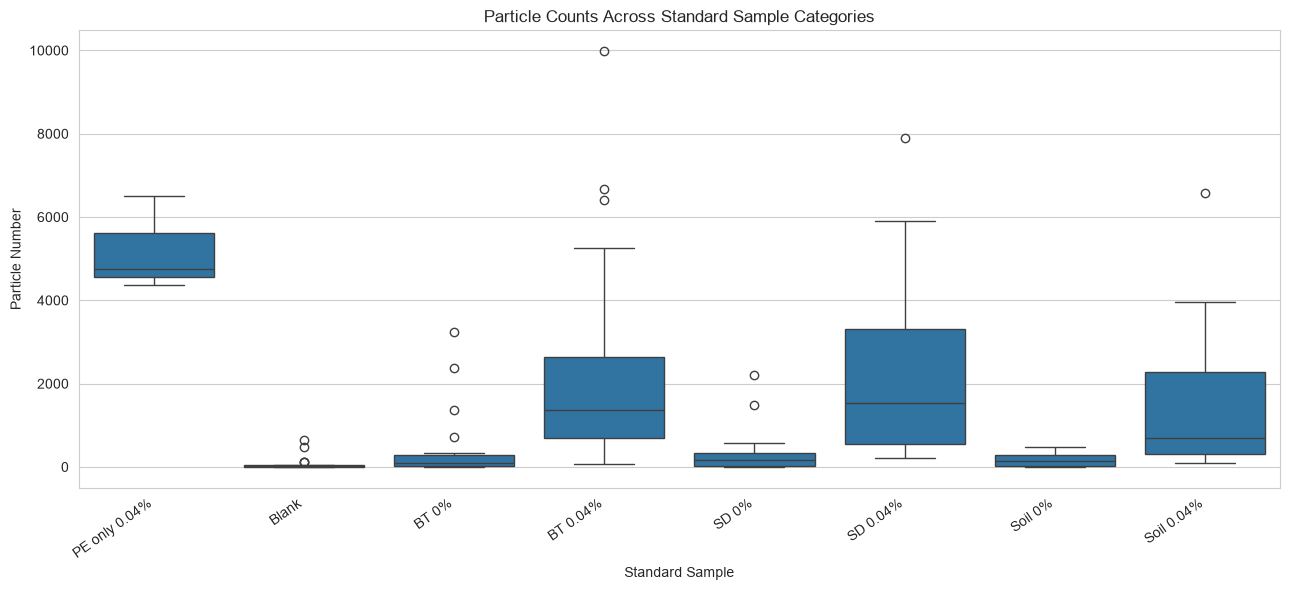

In [51]:


if data["std_quant"] is not None:

    stdq = standardise_columns(
        data["std_quant"]
    )

    stdq = standardise_missing(stdq)

    if "Particle_number" in stdq.columns:

        stdq["Particle_number"] = pd.to_numeric(
            stdq["Particle_number"],
            errors="coerce"
        )

    if "Rep" in stdq.columns:

        stdq["Rep"] = pd.to_numeric(
            stdq["Rep"],
            errors="coerce"
        )

    if "Sample" in stdq.columns:

        stdq["Sample"] = (
            stdq["Sample"].astype("string").str.strip()
        )

        print("\nStandard Sample Categories:")

        print(stdq["Sample"].value_counts(dropna=False))

        # Summary by sample

        sample_summary = stdq.groupby(
            "Sample"
        )["Particle_number"].agg(
            ["count", "mean", "median", "std", "min", "max"]
        ).round(2)

        print("\nStandard Quantification by Sample:")

        display(sample_summary)

        sample_summary.to_csv(
            os.path.join(
                TABLE_DIR,
                "standard_quantification_by_sample.csv"
            )
        )

        # Summary by country and sample

        if "Country" in stdq.columns:

            country_sample_summary = stdq.groupby(
                ["Country", "Sample"]
            )["Particle_number"].agg(
                ["count", "mean", "median", "std", "min", "max"]
            ).round(2)

            display(country_sample_summary)

            country_sample_summary.to_csv(
                os.path.join(
                    TABLE_DIR,
                    "standard_quantification_by_country_sample.csv"
                )
            )

        # Visualise individual sample categories

        plt.figure(figsize=(13, 6))

        sns.boxplot(
            data=stdq,
            x="Sample",
            y="Particle_number"
        )

        plt.title("Particle Counts Across Standard Sample Categories")
        plt.xlabel("Standard Sample")
        plt.ylabel("Particle Number")

        plt.xticks(rotation=35, ha="right")

        save_figure("fig11_standard_quantification.png")


        


21A. REPLICATE VARIABILITY


REPLICATE VARIABILITY ANALYSIS

Replicate Variability by Country and Sample:


Replicate_Count     Mean  Standard_Deviation  \
Country   Sample                                                        
Australia BT 0%                        4   209.85               94.66   
          BT 0.04%                     4  1282.65             1241.73   
          Blank                        4     3.05                2.50   
          SD 0%                        4   289.05              188.17   
          SD 0.04%                     4   406.00              358.45   
          Soil 0%                      4   235.95               89.01   
          Soil 0.04%                   4   687.10              337.34   
China_1   BT 0%                        3   352.67              340.41   
          BT 0.04%                     3  7211.33             2465.25   
          Blank                        9    11.11                7.45   
          SD 0%                        3   150.00              111.30   
          SD 0.04%                     3  5926.67             1963.08   
          Soil 0%                      3   260.00              118.05   
          Soil 0.04%                   3  1622.67              833.44   
China_2   BT 0%                        3    93.33               15.28   
          BT 0.04%                     3  1653.33              258.91   
          Blank                        3    30.00               26.46   
          SD 0%                        3   306.67              172.14   
          SD 0.04%                     3  3633.33              831.71   
          Soil 0%                      3   183.33               87.37   
          Soil 0.04%                   3  4390.00             1897.39   
Egypt     BT 0%                        4   228.11               94.04   
          BT 0.04%                     5   253.06              177.63   
          Blank                        3   117.61                7.98   
          SD 0%                        3   291.54               40.90   
          SD 0.04%                     3   544.07               20.11   
          Soil 0%                      4   322.26              146.79   
          Soil 0.04%                   3   458.42              302.69   
India     BT 0%                        3    51.54               31.90   
          BT 0.04%                     3  1310.21              222.93   
          Blank                        3    25.77                5.24   
          SD 0%                        3    30.39                6.37   
          SD 0.04%                     3  2320.45             1224.98   
          Soil 0%                      3    12.55                4.99   
          Soil 0.04%                   3   259.00              119.92   
Sri Lanka BT 0%                        3  2327.36              947.33   
          BT 0.04%                     3  3517.24             2733.20   
          Blank                        3   381.73              308.13   
          SD 0%                        3  1429.89              814.38   
          SD 0.04%                     3  1097.01              431.81   
          Soil 0%                      3   189.43              200.19   
          Soil 0.04%                   3   592.18              519.30   
UK        BT 0%                        3     9.14                0.72   
          BT 0.04%                     3   595.64              451.30   
          Blank                        3    12.88                1.90   
          PE only 0.04%                3  5209.14             1139.82   
          SD 0%                        3     7.89                3.81   
          SD 0.04%                     3  1040.91              889.13   
          Soil 0%                      3    10.80                2.59   
          Soil 0.04%                   3   205.19              131.54   
Vietnam   BT 0%                        3     2.27                0.64   
          BT 0.04%                     3  3408.00             1072.53   
          Blank                        3     1.00                0.53   
          

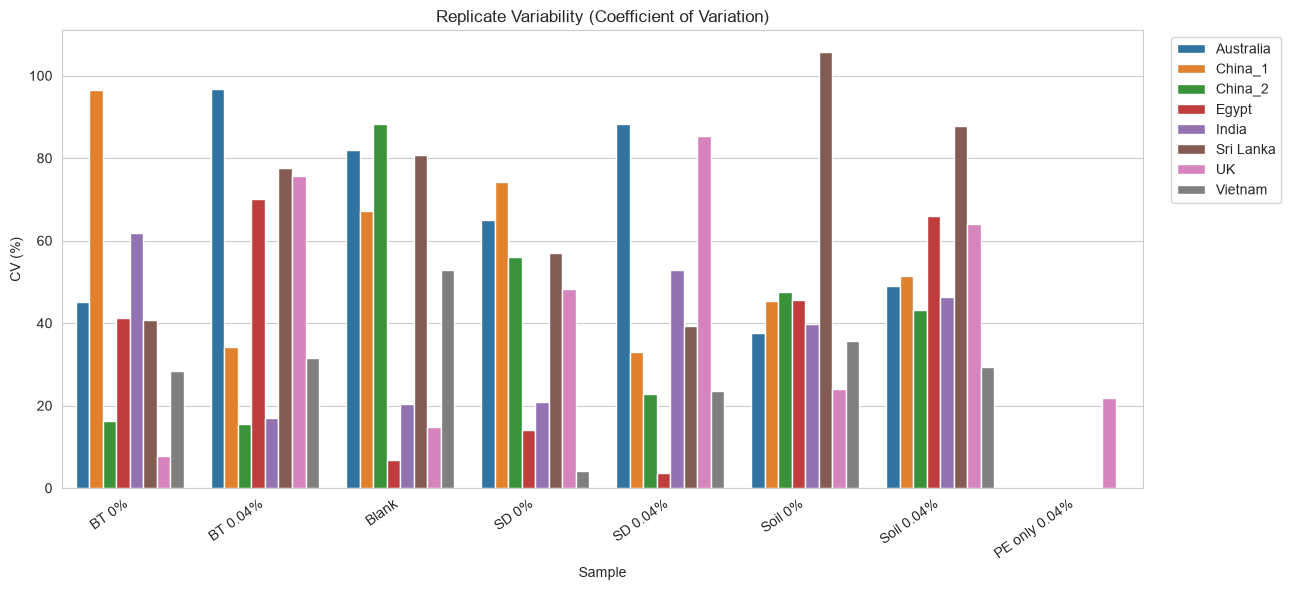

In [52]:


print("\nREPLICATE VARIABILITY ANALYSIS")

if {"Country", "Sample", "Rep", "Particle_number"}.issubset(stdq.columns):

    replicate_summary = stdq.groupby(
        ["Country", "Sample"]
    )["Particle_number"].agg(
        Replicate_Count="count",
        Mean="mean",
        Standard_Deviation="std",
        Minimum="min",
        Maximum="max"
    )

    replicate_summary["CV_Percent"] = np.where(
        replicate_summary["Mean"] != 0,
        (
            replicate_summary["Standard_Deviation"]
            / replicate_summary["Mean"]
        ) * 100,
        np.nan
    )

    replicate_summary = replicate_summary.round(2)

    print("\nReplicate Variability by Country and Sample:")

    display(replicate_summary)

    replicate_summary.to_csv(
        os.path.join(
            TABLE_DIR,
            "replicate_variability_by_country_sample.csv"
        )
    )

    # CV comparison plot

    cv_plot = (
        replicate_summary
        .reset_index()
        .dropna(subset=["CV_Percent"])
    )

    if not cv_plot.empty:

        plt.figure(figsize=(13, 6))

        sns.barplot(
            data=cv_plot,
            x="Sample",
            y="CV_Percent",
            hue="Country"
        )

        plt.title(
            "Replicate Variability (Coefficient of Variation)"
        )

        plt.xlabel("Sample")
        plt.ylabel("CV (%)")

        plt.xticks(rotation=35, ha="right")

        plt.legend(
            bbox_to_anchor=(1.02, 1),
            loc="upper left"
        )

        save_figure("fig12_replicate_cv.png")

    else:

        print("CV plot skipped: no non-zero group means.")

else:

    print(
        "Replicate variability skipped: "
        "required columns are missing."
    )

21B. SPIKED AND UNSPIKED COMPARISON

In [53]:


if {"Country", "Sample", "Particle_number"}.issubset(stdq.columns):

    comparison_rows = []

    for country in stdq["Country"].dropna().unique():

        for material in ["BT", "SD", "Soil"]:

            zero_sample = stdq.loc[
                (stdq["Country"] == country)
                & (stdq["Sample"] == f"{material} 0%"),
                "Particle_number"
            ].dropna()

            spiked_sample = stdq.loc[
                (stdq["Country"] == country)
                & (stdq["Sample"] == f"{material} 0.04%"),
                "Particle_number"
            ].dropna()

            if len(zero_sample) > 0 and len(spiked_sample) > 0:

                comparison_rows.append({

                    "Country": country,
                    "Material": material,

                    "Unspiked_Count": len(zero_sample),

                    "Unspiked_Mean": zero_sample.mean(),

                    "Spiked_Count": len(spiked_sample),

                    "Spiked_Mean": spiked_sample.mean(),

                    "Mean_Difference": (
                        spiked_sample.mean()
                        - zero_sample.mean()
                    )

                })

    spiked_comparison = pd.DataFrame(comparison_rows)

    print("\nSpiked vs Unspiked Comparison:")

    display(spiked_comparison)

    spiked_comparison.to_csv(
        os.path.join(
            TABLE_DIR,
            "spiked_unspiked_comparison.csv"
        ),
        index=False
    )

else:

    print(
        "Spiked vs unspiked comparison skipped: "
        "required columns are missing."
    )


Spiked vs Unspiked Comparison:


,Country,Material,Unspiked_Count,Unspiked_Mean,Spiked_Count,Spiked_Mean,Mean_Difference
0,UK,BT,3,9.138110,3,595.638629,586.500519
1,UK,SD,3,7.892004,3,1040.913811,1033.021807
2,UK,Soil,3,10.799585,3,205.192108,194.392523
3,Vietnam,BT,3,2.266667,3,3408.000000,3405.733333
4,Vietnam,SD,3,2.866667,3,2673.333333,2670.466667
5,Vietnam,Soil,3,3.400000,3,2974.000000,2970.600000
6,Egypt,BT,4,228.112626,5,253.057633,24.945007
7,Egypt,SD,3,291.538349,3,544.068045,252.529696
8,Egypt,Soil,4,322.261329,3,458.424989,136.163660
9,China_1,BT,3,352.666667,3,7211.333333,6858.666667


22. LABORATORY METADATA ANALYSIS

In [54]:
if data["lab_meta"] is not None:

    lab = standardise_columns(
        data["lab_meta"]
    )

    lab = standardise_missing(lab)

    print("\nLaboratory Metadata Shape:", lab.shape)

    print("\nLaboratory Metadata Columns:")
    print(lab.columns.tolist())

    display(lab.head())

    # Metadata completeness

    metadata_summary = pd.DataFrame({

        "Data_Type": lab.dtypes.astype(str),

        "Missing_Count": lab.isna().sum(),

        "Missing_Percentage": (
            lab.isna().mean() * 100
        ).round(2),

        "Unique_Values": lab.nunique()

    })

    print("\nLaboratory Metadata Completeness:")

    display(metadata_summary)

    metadata_summary.to_csv(
        os.path.join(
            TABLE_DIR,
            "laboratory_metadata_summary.csv"
        )
    )

    # Examine laboratory differences by country

    if "Country" in lab.columns:

        lab["Country"] = (
            lab["Country"].astype("string").str.strip()
        )

        print("\nLaboratory Metadata by Country:")

        display(lab.sort_values("Country"))

        lab.to_csv(
            os.path.join(
                OUTPUT_DIR,
                "laboratory_metadata_cleaned.csv"
            ),
            index=False
        )

        # Inspect important methodological fields when available

        important_metadata = [
            "Instrument_manufacturer",
            "Instrument_manufacture_r",
            "Instrument_type",
            "Instrument_model",
            "Location",
            "Library",
            "Soil_weight",
            "Membrane_area",
            "Image_size",
            "Membrane_d",
            "Real_membrane_d"
        ]

        available_metadata = [
            col for col in important_metadata
            if col in lab.columns
        ]

        if available_metadata:

            metadata_comparison = lab[
                ["Country"] + available_metadata
            ].copy()

            print("\nLaboratory Method and Instrument Comparison:")

            display(metadata_comparison)

            metadata_comparison.to_csv(
                os.path.join(
                    TABLE_DIR,
                    "laboratory_method_comparison.csv"
                ),
                index=False
            )




Laboratory Metadata Shape: (8, 45)

Laboratory Metadata Columns:
['Country', 'Instrument_manufacturer', 'Instrument_type', 'Instrument_model', 'Location', 'Library', 'Soil_weight', 'Soil_classification', 'Soil_texture', 'Membrane_area', 'Image_size', 'Membrane_d', 'Real_membrane_d', 'Real_membrane_a', 'Membrane_type', 'Pore_size', 'Membrane_manufacturer', 'Membrane_product_number', 'Filtration_system_manufacturer', 'Vacuum_pump_manufacturer', 'Vacuum_pump_type', 'Microscope_manufacturer', 'Microscope_model', 'Excitation_wavelength', 'Emission_wavelength', 'Location.1', 'Nile_Red_manufacturer', 'Nile_red_product_number', 'Nile_red_purity', 'Nile_red_CAS_number', 'Polyethylene_manufacturer', 'Polyethylene_product_number', 'Polyethylene_CAS_number', 'SD_manufacturer', 'SD_product_number', 'SD_CAS_number', 'BT_manufacturer', 'BT_product_number', 'BT_CAS_number', 'NaOH_manufacturer', 'NaOH_product_number', 'NaOH_CAS_number', 'NaCl_manufacturer', 'NaCl_product_number', 'NaCl_CAS_number']


,Country,Instrument_manufacturer,Instrument_type,Instrument_model,Location,Library,Soil_weight,Soil_classification,Soil_texture,Membrane_area,...,SD_CAS_number,BT_manufacturer,BT_product_number,BT_CAS_number,NaOH_manufacturer,NaOH_product_number,NaOH_CAS_number,NaCl_manufacturer,NaCl_product_number,NaCl_CAS_number
0,UK,Agilent,Quantum cascade laser direct infrared system,LDIR 8700,Bangor University (UK),Instrument library (Agilent Microplastic Start...,5 ± 0.05,Cambisol,Clay-loam,16.05,...,60676-86-0,Sigma Aldrich,285234.0,1302-78-9,Sigma Aldrich,221465,1310-73-2,Sigma Aldrich,S9888,7647-14-5
1,China 1,Bruker,µFTIR,Lumos II,Chinese Academy of Agricultural Sciences (China),Instrument library (incorporated polymer-speci...,5 ± 0.05,Cambisol,Loam,5.00,...,NaN,NaN,NaN,NaN,Heng Xing,30225,NaN,Heng Xing,30144,NaN
2,China 2,NaN,NaN,NaN,NaN,NaN,5 ± 0.05,Umbrisol,Loam,2.00,...,NaN,NaN,NaN,NaN,Sinopharm Chemical Reagent,UN No.1823,NaN,Sinopharm Chemical Reagent,10019318,NaN
3,Egypt,Bruker,ATR-FTIR,Alpha II,Mansoura University (Egypt),Open Specy (1),5 ± 0.05,Arenosol,Sand,22.74,...,NaN,NaN,NaN,NaN,Alpha Chemika,AL4159,NaN,Alpha Chemika,AL4105,NaN
4,Sri Lanka,NaN,NaN,NaN,NaN,NaN,2.5 ± 0.05,Luvisol,Sandy-clay-loam,14.50,...,NaN,NaN,NaN,NaN,Chem-Lab,CL00.1492,NaN,Loba Chemie Pvt. Ltd.,5820,NaN



Laboratory Metadata Completeness:


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
Country,str,0,0.0,8
Instrument_manufacturer,str,2,25.0,5
Instrument_type,str,2,25.0,5
Instrument_model,str,2,25.0,6
Location,str,2,25.0,6
Library,str,2,25.0,4
Soil_weight,str,0,0.0,3
Soil_classification,str,0,0.0,6
Soil_texture,str,0,0.0,7
Membrane_area,float64,0,0.0,7



Laboratory Metadata by Country:


,Country,Instrument_manufacturer,Instrument_type,Instrument_model,Location,Library,Soil_weight,Soil_classification,Soil_texture,Membrane_area,...,SD_CAS_number,BT_manufacturer,BT_product_number,BT_CAS_number,NaOH_manufacturer,NaOH_product_number,NaOH_CAS_number,NaCl_manufacturer,NaCl_product_number,NaCl_CAS_number
7,Australia,Thermo Fisher Scientific,µ-ATR-FTIR,Nicolet iN10 MX,Curtin University (Australia),Instrument library (incorporated polymer-speci...,5 ± 0.05,Arenosol,Sand,100.00,...,NaN,NaN,NaN,NaN,Row Scientific,CK150515,NaN,Chem-Supply,9.32641E+12,NaN
1,China 1,Bruker,µFTIR,Lumos II,Chinese Academy of Agricultural Sciences (China),Instrument library (incorporated polymer-speci...,5 ± 0.05,Cambisol,Loam,5.00,...,NaN,NaN,NaN,NaN,Heng Xing,30225,NaN,Heng Xing,30144,NaN
2,China 2,NaN,NaN,NaN,NaN,NaN,5 ± 0.05,Umbrisol,Loam,2.00,...,NaN,NaN,NaN,NaN,Sinopharm Chemical Reagent,UN No.1823,NaN,Sinopharm Chemical Reagent,10019318,NaN
3,Egypt,Bruker,ATR-FTIR,Alpha II,Mansoura University (Egypt),Open Specy (1),5 ± 0.05,Arenosol,Sand,22.74,...,NaN,NaN,NaN,NaN,Alpha Chemika,AL4159,NaN,Alpha Chemika,AL4105,NaN
6,India,Perkin Elmer,µFTIR,Spectrum 3 with Spotlight 200i,CIPET (India),Open Specy (1),5 ± 0.05,Vertisol,Clay,10.09,...,NaN,NaN,NaN,NaN,Sigma Aldrich,NaN,NaN,Sigma Aldrich,NaN,NaN
4,Sri Lanka,NaN,NaN,NaN,NaN,NaN,2.5 ± 0.05,Luvisol,Sandy-clay-loam,14.50,...,NaN,NaN,NaN,NaN,Chem-Lab,CL00.1492,NaN,Loba Chemie Pvt. Ltd.,5820,NaN
0,UK,Agilent,Quantum cascade laser direct infrared system,LDIR 8700,Bangor University (UK),Instrument library (Agilent Microplastic Start...,5 ± 0.05,Cambisol,Clay-loam,16.05,...,60676-86-0,Sigma Aldrich,285234.0,1302-78-9,Sigma Aldrich,221465,1310-73-2,Sigma Aldrich,S9888,7647-14-5
5,Vietnam,Thermo Fisher Scientific\n,µ-ATR-FTIR,Nicolet iN10 MX,Hanoi University of Science and Technology (Vi...,Instrument library (incorporated polymer-speci...,5 ± 0.05,Acrisol,Sandy-silt-loam,100.00,...,NaN,NaN,NaN,NaN,Xi-Long,NaN,NaN,Xi-Long,NaN,NaN



Laboratory Method and Instrument Comparison:


,Country,Instrument_manufacturer,Instrument_type,Instrument_model,Location,Library,Soil_weight,Membrane_area,Image_size,Membrane_d,Real_membrane_d
0,UK,Agilent,Quantum cascade laser direct infrared system,LDIR 8700,Bangor University (UK),Instrument library (Agilent Microplastic Start...,5 ± 0.05,16.05,3.7 x 4.92,47,38
1,China 1,Bruker,µFTIR,Lumos II,Chinese Academy of Agricultural Sciences (China),Instrument library (incorporated polymer-speci...,5 ± 0.05,5.00,2.49 x 1.87,50,40
2,China 2,NaN,NaN,NaN,NaN,NaN,5 ± 0.05,2.00,1.80 x 1.30,50,40
3,Egypt,Bruker,ATR-FTIR,Alpha II,Mansoura University (Egypt),Open Specy (1),5 ± 0.05,22.74,6.17 x 4.63,47,40
4,Sri Lanka,NaN,NaN,NaN,NaN,NaN,2.5 ± 0.05,14.50,3.57 x 4.74,47,35
5,Vietnam,Thermo Fisher Scientific\n,µ-ATR-FTIR,Nicolet iN10 MX,Hanoi University of Science and Technology (Vi...,Instrument library (incorporated polymer-speci...,5 ± 0.05,100.00,1.7 x 0.96,47,40
6,India,Perkin Elmer,µFTIR,Spectrum 3 with Spotlight 200i,CIPET (India),Open Specy (1),5 ± 0.05,10.09,3.64 x 3.48,47,40
7,Australia,Thermo Fisher Scientific,µ-ATR-FTIR,Nicolet iN10 MX,Curtin University (Australia),Instrument library (incorporated polymer-speci...,5 ± 0.05,100.00,2.07 x 2.87,47,37


23. IQR OUTLIER ANALYSIS

In [55]:
print("\n" + "=" * 65)
print("IQR OUTLIER ANALYSIS")
print("=" * 65)

outlier_rows = []

for variable in ["MP_number", "pH", "EC", "NH4", "NO3", "DOC", "PO4"]:

    if variable not in master.columns:
        continue

    values = master[variable].dropna()

    if len(values) < 4:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    flagged = values[
        (values < lower_bound)
        | (values > upper_bound)
    ]

    outlier_rows.append({

        "Variable": variable,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Potential_Outlier_Count": len(flagged)

    })


outlier_summary = pd.DataFrame(outlier_rows)

display(outlier_summary)

outlier_summary.to_csv(
    os.path.join(TABLE_DIR, "iqr_outlier_summary.csv"),
    index=False
)

print(
    "Potential outliers are flagged for investigation. "
    "No observations have been removed."
)



IQR OUTLIER ANALYSIS


,Variable,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Potential_Outlier_Count
0,MP_number,10.0000,826.554519,816.554519,-1214.831779,2051.386298,48
1,pH,6.4675,8.020000,1.552500,4.138750,10.348750,2
2,EC,42.8250,312.250000,269.425000,-361.312500,716.387500,28
3,NH4,4.7750,22.552500,17.777500,-21.891250,49.218750,63
4,NO3,6.2000,29.467500,23.267500,-28.701250,64.368750,72
5,DOC,65.0000,172.920000,107.920000,-96.880000,334.800000,56
6,PO4,20.0500,149.022500,128.972500,-173.408750,342.481250,105


Potential outliers are flagged for investigation. No observations have been removed.


24. SAVE CLEANED DATASETS

In [56]:
cleaned_datasets = {

    "mp_quantification_cleaned": mpq,

    "soil_properties_cleaned": soil,

    "questionnaire_cleaned": qn,

    "master_soil_microplastics": master

}

for name, df in cleaned_datasets.items():

    df.to_csv(
        os.path.join(OUTPUT_DIR, name + ".csv"),
        index=False
    )

25. PREPROCESSING SUMMARY

In [57]:
summary_rows = []

for name, df in data.items():

    if df is None:
        continue

    summary_rows.append({

        "Dataset": name,

        "Rows": len(df),

        "Columns": df.shape[1],

        "Duplicate_Rows": int(df.duplicated().sum()),

        "Missing_Cells": int(df.isna().sum().sum())

    })


prep_summary = pd.DataFrame(summary_rows)

print("\n" + "=" * 65)
print("PREPROCESSING SUMMARY")
print("=" * 65)

display(prep_summary)

prep_summary.to_csv(
    os.path.join(TABLE_DIR, "preprocessing_summary.csv"),
    index=False
)


PREPROCESSING SUMMARY


,Dataset,Rows,Columns,Duplicate_Rows,Missing_Cells
0,mp_quant,576,5,0,8
1,soil_props,576,9,0,6
2,questionnaire,192,49,0,656
3,mp_id,6851,5,236,0
4,std_quant,188,4,0,0
5,std_polymer,1440,5,0,220
6,std_lib_uk,180,5,0,0
7,lab_meta,8,45,0,98


26. FINAL PROJECT OUTPUT

In [58]:
print("\n" + "=" * 65)
print("PROJECT ANALYSIS COMPLETED")
print("=" * 65)

print("\nMain outputs:")
print("- Cleaned datasets")
print("- Master survey dataset")
print("- Country concentration summary")
print("- Spearman correlation results")
print("- Polymer identification analysis")
print("- Duplicate sensitivity analysis")
print("- Standard polymer match quality")
print("- Polymer library comparison")
print("- Standard quantification analysis")
print("- Replicate variability and CV")
print("- Spiked vs unspiked comparison")
print("- Laboratory metadata comparison")
print("- IQR outlier report")
print("- Preprocessing summary")

print("\nFigures saved in:", FIG_DIR)
print("Tables saved in:", TABLE_DIR)
print("Cleaned datasets saved in:", OUTPUT_DIR)

print("\nGenerated figures:")

for filename in sorted(os.listdir(FIG_DIR)):
    print(filename)

print("\nGenerated tables:")

for filename in sorted(os.listdir(TABLE_DIR)):
    print(filename)



PROJECT ANALYSIS COMPLETED

Main outputs:
- Cleaned datasets
- Master survey dataset
- Country concentration summary
- Spearman correlation results
- Polymer identification analysis
- Duplicate sensitivity analysis
- Standard polymer match quality
- Polymer library comparison
- Standard quantification analysis
- Replicate variability and CV
- Spiked vs unspiked comparison
- Laboratory metadata comparison
- IQR outlier report
- Preprocessing summary

Figures saved in: figures
Tables saved in: tables
Cleaned datasets saved in: cleaned_data

Generated figures:
fig10_library_comparison.png
fig11_standard_quantification.png
fig12_replicate_cv.png
fig1_missing_before_after.png
fig2_raw_vs_log.png
fig3_depth_trend.png
fig4_distribution.png
fig5_spearman_heatmap.png
fig6_top_polymers.png
fig7_polymer_composition.png
fig8_environmental_match_quality.png
fig9_standard_polymer_quality.png

Generated tables:
environmental_match_quality_by_country.csv
initial_data_quality_report.csv
iqr_outlier_su